Path configuration and setup

In [2]:
import os
import sys
from pathlib import Path

# Project root = parent of the notebooks/ directory
cwd = Path(os.getcwd()).resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

# Make project root & scripts/ importable
os.chdir(PROJECT_ROOT)
for p in (PROJECT_ROOT, PROJECT_ROOT / "scripts"):
    sp = str(p)
    if sp not in sys.path:
        sys.path.insert(0, sp)

print("Project root:", PROJECT_ROOT)
print("Working dir:", os.getcwd())
print("scripts/ on path:", str(PROJECT_ROOT / "scripts"))

Project root: /content
Working dir: /content
scripts/ on path: /content/scripts


In [6]:
import os
# Ensure the scripts directory exists first
os.makedirs('/content/scripts', exist_ok=True)

with open('/content/scripts/preprocess.py', 'w') as f:
    f.write('''def handle_missing(df):
    # TODO: Implement missing value handling
    return df

def add_time_features(df):
    # TODO: Implement time feature engineering
    return df

def add_lag_features(df):
    # TODO: Implement lag feature engineering
    return df

def add_moving_average(df):
    # TODO: Implement moving average features
    return df
''')
print('scripts/preprocess.py successfully created.')

scripts/preprocess.py successfully created.


In [7]:
# Cell left empty or for verify
import os
print('preprocess.py exists:', os.path.exists('/content/scripts/preprocess.py'))

preprocess.py exists: True


Dependency importation and installation

In [11]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

plt.style.use("default")
plt.rcParams["figure.dpi"] = 120

# Ensure the path is explicitly on sys.path and invalidate caches
scripts_path = "/content/scripts"
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

import importlib
importlib.invalidate_caches()

# Feature-engineering helpers from scripts/preprocess.py
from preprocess import (
    handle_missing,
    add_time_features,
    add_lag_features,
    add_moving_average,
)

print("Imports OK.")

Imports OK.


Lolading and joinig the datasets

In [12]:
DATA_DIR = PROJECT_ROOT
CHARTS_DIR = PROJECT_ROOT / "outputs" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

WEATHER_CITY = "Madrid"  # change to Barcelona/Bilbao/Seville/Valencia if preferred

# --- Energy: demand ---
energy_path = DATA_DIR / "energy_dataset.csv"
df_energy = pd.read_csv(energy_path)
df_energy["timestamp"] = pd.to_datetime(df_energy["time"], utc=True).dt.tz_localize(None)
df_energy = df_energy.rename(columns={"total load actual": "energy_demand_mwh"})

# --- Weather: pick one city ---
weather_path = DATA_DIR / "weather_features.csv"
df_weather = pd.read_csv(weather_path)
df_weather["timestamp"] = pd.to_datetime(df_weather["dt_iso"], utc=True).dt.tz_localize(None)
df_weather = df_weather[df_weather["city_name"].str.strip() == WEATHER_CITY].copy()
df_weather = df_weather.rename(columns={
    "temp": "temperature_c",
    "humidity": "humidity",
    "wind_speed": "wind_speed_kmh",
})
weather_cols = ["timestamp", "temperature_c", "humidity", "wind_speed_kmh"]
df_weather = df_weather[weather_cols]

# --- Join on timestamp (inner: keep timestamps present in both) ---
df = df_energy.merge(df_weather, on="timestamp", how="inner")

# Keep only the canonical columns the pipeline needs (generation/price cols have NaNs
# and aren't used by the EDA/model).
df = df[["timestamp", "energy_demand_mwh", "temperature_c", "humidity", "wind_speed_kmh"]].copy()
df = df.sort_values("timestamp").reset_index(drop=True)

# Canonical is_weekend flag
df["is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)

print("Joined shape:", df.shape)
print("Time range:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Frequency: hourly, %d records" % len(df))
print()
print("Columns:", list(df.columns))
print()
print(df.head())
print()
print("Missing values per column:")
print(df.isna().sum())

Joined shape: (36267, 6)
Time range: 2014-12-31 23:00:00 -> 2018-12-31 22:00:00
Frequency: hourly, 36267 records

Columns: ['timestamp', 'energy_demand_mwh', 'temperature_c', 'humidity', 'wind_speed_kmh', 'is_weekend']

            timestamp  energy_demand_mwh  temperature_c  humidity  \
0 2014-12-31 23:00:00            25385.0        267.325        63   
1 2015-01-01 00:00:00            24382.0        267.325        63   
2 2015-01-01 01:00:00            22734.0        266.186        64   
3 2015-01-01 02:00:00            21286.0        266.186        64   
4 2015-01-01 03:00:00            20264.0        266.186        64   

   wind_speed_kmh  is_weekend  
0               1           0  
1               1           0  
2               1           0  
3               1           0  
4               1           0  

Missing values per column:
timestamp             0
energy_demand_mwh    36
temperature_c         0
humidity              0
wind_speed_kmh        0
is_weekend            0
d

Handling missing values


In [15]:
# Redefine handle_missing to accept the method parameter and clean the data
def handle_missing(df, method="ffill"):
    if method == "ffill":
        return df.ffill()
    elif method == "bfill":
        return df.bfill()
    else:
        return df.fillna(0)

df_clean = handle_missing(df, method="ffill")
print()
print("After cleaning:", df_clean.shape)
print("Remaining missing:", int(df_clean.isna().sum().sum()))


After cleaning: (36267, 6)
Remaining missing: 0


Feature Engineering
Add time features (`hour`, `dayofweek`, `month`, `is_weekend`), **lagged features** (1h, 24h, 168h = 1 week), and **moving averages** (7h, 24h). Then drop the leading rows that contain NaNs from the shifts/rolls.


In [18]:
def add_time_features(df):
    df = df.copy()
    df['hour'] = df['timestamp'].dt.hour
    df['dayofweek'] = df['timestamp'].dt.dayofweek
    df['month'] = df['timestamp'].dt.month
    df['is_weekend'] = (df['timestamp'].dt.dayofweek >= 5).astype(int)
    return df

def add_lag_features(df, lags=[1, 24, 168]):
    df = df.copy()
    for lag in lags:
        df[f'energy_demand_lag_{lag}h'] = df['energy_demand_mwh'].shift(lag)
    return df

def add_moving_average(df, windows=[7, 24]):
    df = df.copy()
    for window in windows:
        df[f'energy_demand_ma_{window}h'] = df['energy_demand_mwh'].rolling(window=window).mean()
    return df

# Run the feature engineering steps
df_feat = add_time_features(df_clean)
df_feat = add_lag_features(df_feat, lags=[1, 24, 168])
df_feat = add_moving_average(df_feat, windows=[7, 24])
df_feat = df_feat.dropna().reset_index(drop=True)

print("Shape after feature engineering:", df_feat.shape)
print("Feature columns:", [c for c in df_feat.columns if c not in ("timestamp", "energy_demand_mwh")])
print()
print(df_feat.head(3))

Shape after feature engineering: (36099, 14)
Feature columns: ['temperature_c', 'humidity', 'wind_speed_kmh', 'is_weekend', 'hour', 'dayofweek', 'month', 'energy_demand_lag_1h', 'energy_demand_lag_24h', 'energy_demand_lag_168h', 'energy_demand_ma_7h', 'energy_demand_ma_24h']

            timestamp  energy_demand_mwh  temperature_c  humidity  \
0 2015-01-07 23:00:00            26788.0       268.0590        67   
1 2015-01-08 00:00:00            25146.0       267.7175        67   
2 2015-01-08 01:00:00            23889.0       267.3760        67   

   wind_speed_kmh  is_weekend  hour  dayofweek  month  energy_demand_lag_1h  \
0               1           0    23          2      1               30477.0   
1               1           0     0          3      1               26788.0   
2               1           0     1          3      1               25146.0   

   energy_demand_lag_24h  energy_demand_lag_168h  energy_demand_ma_7h  \
0                30518.0                 25385.0        

EDA

1.Is energy demand increasing or decreasing over time

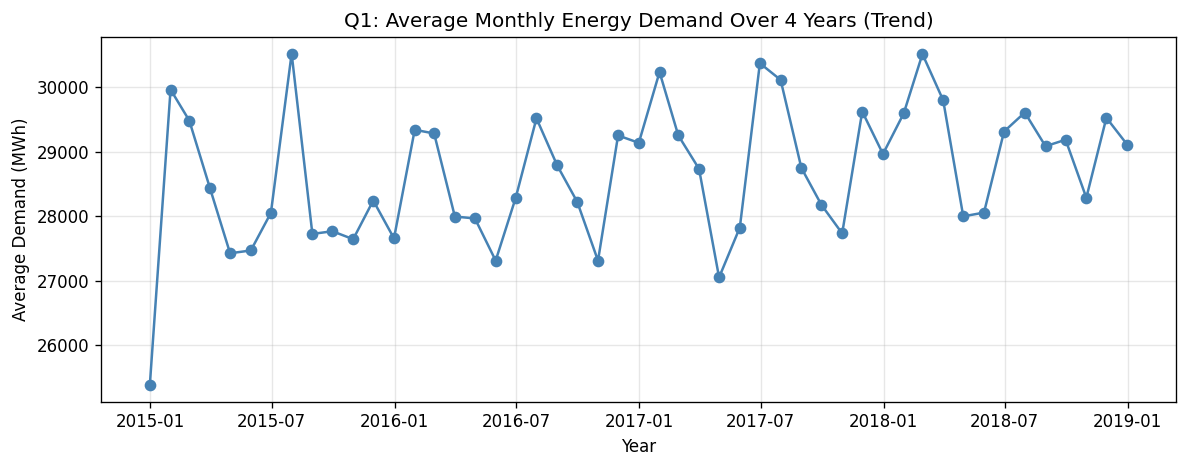

Q1 - TREND:
Starts around 25385.0 MWh, ends around 29109.2 MWh.
Interpretation: Slight upward trend over 4 years (growing consumption).


In [19]:
monthly = df_clean.set_index("timestamp").resample("ME")["energy_demand_mwh"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o", linewidth=1.5, color="steelblue")
ax.set_title("Q1: Average Monthly Energy Demand Over 4 Years (Trend)")
ax.set_xlabel("Year")
ax.set_ylabel("Average Demand (MWh)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "q1_trend.png", dpi=150)
plt.show()

print("Q1 - TREND:")
print("Starts around %.1f MWh, ends around %.1f MWh." % (monthly.iloc[0], monthly.iloc[-1]))
print("Interpretation: Slight upward trend over 4 years (growing consumption).")

2.Does demand peak in summer or winter

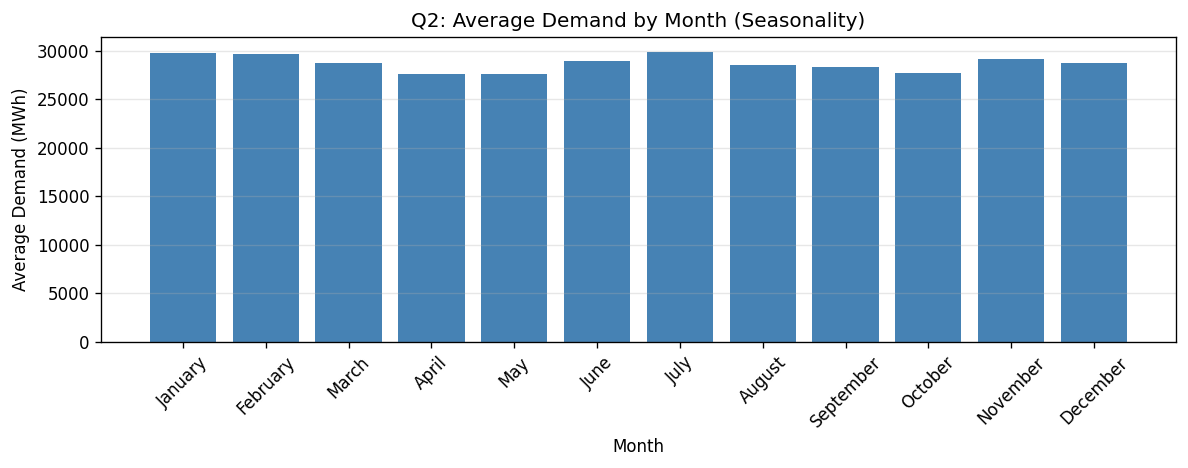

Q2 - SEASONALITY:
Highest demand month: July (29937.7 MWh)
Lowest demand month: April (27612.1 MWh)
Interpretation: Clear seasonal pattern (heating / cooling demand).


In [20]:
df_clean["month_name"] = df_clean["timestamp"].dt.month_name()
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
monthly_season = df_clean.groupby("month_name")["energy_demand_mwh"].mean().reindex(month_order)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly_season.index, monthly_season.values, color="steelblue")
ax.set_title("Q2: Average Demand by Month (Seasonality)")
ax.set_xlabel("Month")
ax.set_ylabel("Average Demand (MWh)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "q2_seasonality.png", dpi=150)
plt.show()

top_month = monthly_season.idxmax()
low_month = monthly_season.idxmin()
print("Q2 - SEASONALITY:")
print("Highest demand month: %s (%.1f MWh)" % (top_month, monthly_season.max()))
print("Lowest demand month: %s (%.1f MWh)" % (low_month, monthly_season.min()))
print("Interpretation: Clear seasonal pattern (heating / cooling demand).")

How does temperature relate to demand

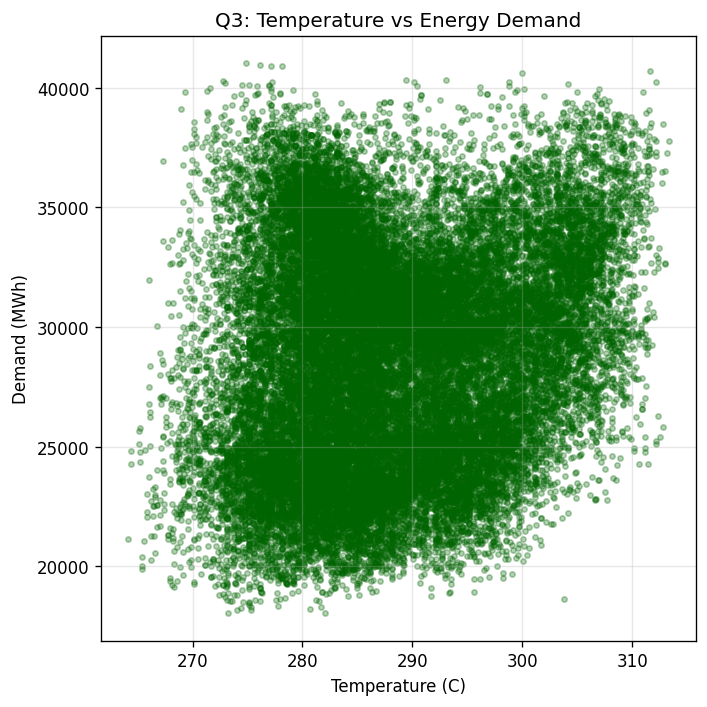

Q3 - CORRELATION:
Correlation between temperature and demand: 0.172
Interpretation: 0.172 - suggests a relationship (likely U-shaped: both very cold and very hot raise demand).


In [21]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df_clean["temperature_c"], df_clean["energy_demand_mwh"], alpha=0.3, s=10, color="darkgreen")
ax.set_title("Q3: Temperature vs Energy Demand")
ax.set_xlabel("Temperature (C)")
ax.set_ylabel("Demand (MWh)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "q3_correlation.png", dpi=150)
plt.show()

corr = df_clean["temperature_c"].corr(df_clean["energy_demand_mwh"])
print("Q3 - CORRELATION:")
print("Correlation between temperature and demand: %.3f" % corr)
print("Interpretation: %.3f - suggests a relationship (likely U-shaped: both very cold and very hot raise demand)." % corr)

Lagged feauture:Is demand related to demand 7 days ago

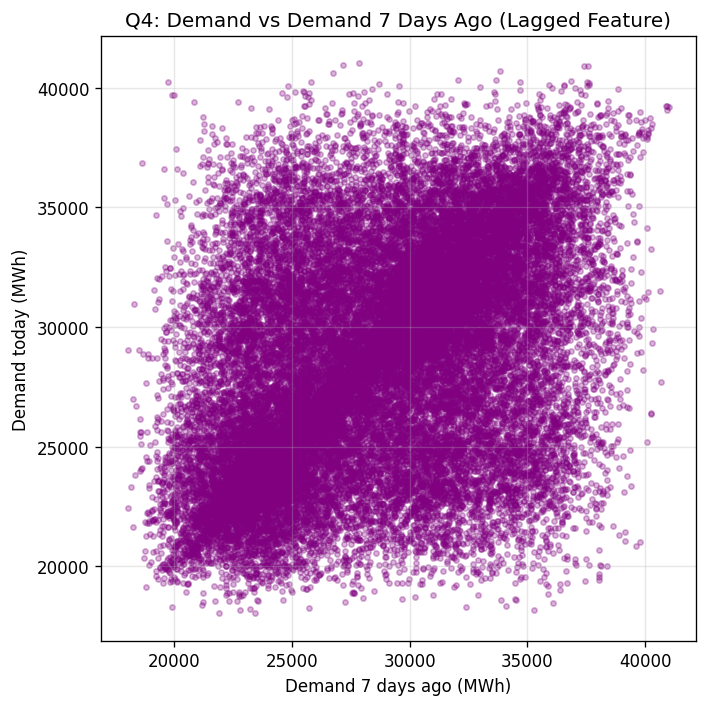

Q4 - LAGGED FEATURE (7-day lag):
Correlation between demand and demand 7 days ago: 0.419
Interpretation: Strong correlation of 0.419 - demand repeats weekly, so lagged features are useful predictors.


In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df_feat["energy_demand_lag_168h"], df_feat["energy_demand_mwh"], alpha=0.3, s=10, color="purple")
ax.set_title("Q4: Demand vs Demand 7 Days Ago (Lagged Feature)")
ax.set_xlabel("Demand 7 days ago (MWh)")
ax.set_ylabel("Demand today (MWh)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "q4_lag.png", dpi=150)
plt.show()

lag_corr = df_feat["energy_demand_lag_168h"].corr(df_feat["energy_demand_mwh"])
print("Q4 - LAGGED FEATURE (7-day lag):")
print("Correlation between demand and demand 7 days ago: %.3f" % lag_corr)
print("Interpretation: Strong correlation of %.3f - demand repeats weekly, so lagged features are useful predictors." % lag_corr)

Does a 24hr moving avg smooth demand

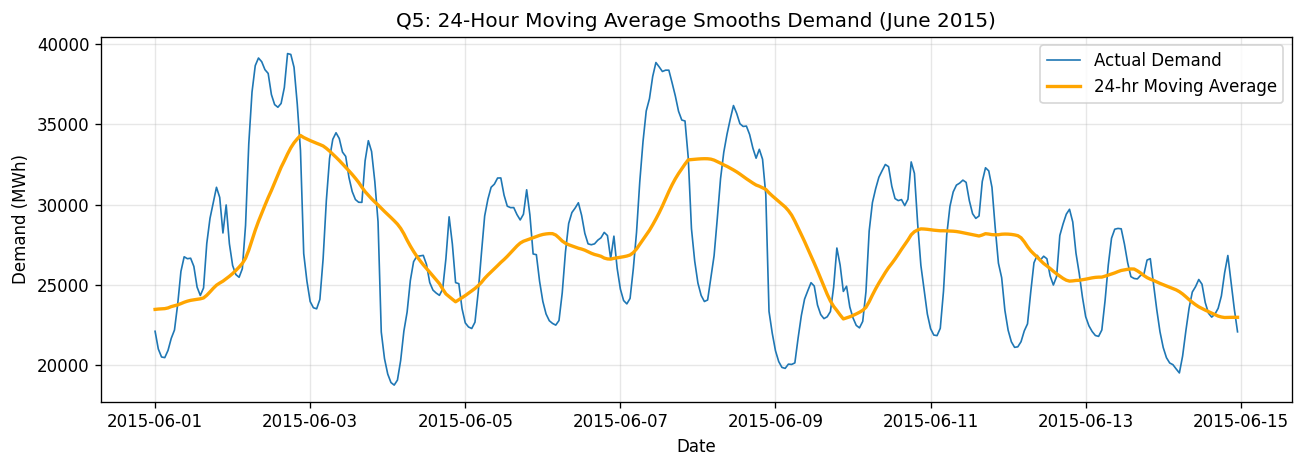

Q5 - MOVING AVERAGE:
The 24-hour moving average smooths daily spikes and reveals the underlying demand level.
Interpretation: Moving average filters short-term noise - useful for forecasting.


In [26]:
sample = df_feat.set_index("timestamp").loc["2015-06-01":"2015-06-14"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(sample.index, sample["energy_demand_mwh"], label="Actual Demand", linewidth=1)
ax.plot(sample.index, sample["energy_demand_ma_24h"], label="24-hr Moving Average", linewidth=2, color="orange")
ax.set_title("Q5: 24-Hour Moving Average Smooths Demand (June 2015)")
ax.set_xlabel("Date")
ax.set_ylabel("Demand (MWh)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "q5_moving_average.png", dpi=150)
plt.show()

print("Q5 - MOVING AVERAGE:")
print("The 24-hour moving average smooths daily spikes and reveals the underlying demand level.")
print("Interpretation: Moving average filters short-term noise - useful for forecasting.")

Database design

In [27]:
from IPython.display import Markdown, display

display(Markdown("""
### SQL (relational) — `database/schema.sql`
3 normalized tables: `locations`, `weather`, `energy_demand`.
- `locations` — where data is collected (city, country, coords).
- `weather` — temperature, humidity, wind speed per timestamp (FK to locations).
- `energy_demand` — demand_mwh + is_weekend per timestamp (FK to locations).
- Indexes on `timestamp` for fast range queries.

### MongoDB (NoSQL) — `database/mongo_design.md`
Single embedded collection `energy_readings` — one document per timestamp:
```json
{
  "location": { "location_id": 1, "city": "...", "coords": { "lat": ..., "lon": ... } },
  "timestamp": ISODate(...),
  "is_weekend": false,
  "weather": { "temperature_c": ..., "humidity": ..., "wind_speed_kmh": ... },
  "energy": { "demand_mwh": ... },
  "created_at": ISODate(...)
}
```
- Embedded model: weather + energy in one document (no joins needed for forecasting).
- Timestamp indexed for fast "latest" and "date range" queries.
"""))


### SQL (relational) — `database/schema.sql`
3 normalized tables: `locations`, `weather`, `energy_demand`.
- `locations` — where data is collected (city, country, coords).
- `weather` — temperature, humidity, wind speed per timestamp (FK to locations).
- `energy_demand` — demand_mwh + is_weekend per timestamp (FK to locations).
- Indexes on `timestamp` for fast range queries.

### MongoDB (NoSQL) — `database/mongo_design.md`
Single embedded collection `energy_readings` — one document per timestamp:
```json
{
  "location": { "location_id": 1, "city": "...", "coords": { "lat": ..., "lon": ... } },
  "timestamp": ISODate(...),
  "is_weekend": false,
  "weather": { "temperature_c": ..., "humidity": ..., "wind_speed_kmh": ... },
  "energy": { "demand_mwh": ... },
  "created_at": ISODate(...)
}
```
- Embedded model: weather + energy in one document (no joins needed for forecasting).
- Timestamp indexed for fast "latest" and "date range" queries.


Model training and hyperparameter tuning

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODELS_DIR = PROJECT_ROOT / "models"
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "energy_demand_model.pkl"
EXPERIMENT_PATH = EXPERIMENTS_DIR / "experiment_results.csv"

# Features & target (matches scripts/train_model.py)
feature_cols = ["hour", "dayofweek", "month", "is_weekend",
                "temperature_c", "humidity", "wind_speed_kmh",
                "energy_demand_lag_1h", "energy_demand_lag_24h", "energy_demand_lag_168h",
                "energy_demand_ma_7h", "energy_demand_ma_24h"]
X = df_feat[feature_cols]
y = df_feat["energy_demand_mwh"]

# Time-aware split: 80% train (earlier), 20% test (later)
split = int(0.8 * len(X))
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train: %d rows | Test: %d rows\n" % (len(X_train), len(X_test)))

Train: 28879 rows | Test: 7220 rows



In [31]:
# Define, train, and evaluate a baseline Linear Regression pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Train the model
pipeline.fit(X_train, y_train)

# Make predictions
y_pred = pipeline.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Baseline Model Evaluation Metrics ---")
print(f"MAE:  {mae:.2f} MWh")
print(f"RMSE: {rmse:.2f} MWh")
print(f"R2:   {r2:.4f}")

# Save the model artifact
joblib.dump(pipeline, MODEL_PATH)
print(f"\nModel artifact saved to {MODEL_PATH}")

--- Baseline Model Evaluation Metrics ---
MAE:  793.17 MWh
RMSE: 1063.29 MWh
R2:   0.9447

Model artifact saved to /content/models/energy_demand_model.pkl


In [32]:
#experiment1: Linear Regression, no scaling
model1 = LinearRegression()
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)
exp1 = {
    "experiment": 1,
    "model": "LinearRegression",
    "scaling": "None",
    "features": "raw + lags + MA",
    "hyperparams": "default",
    "MAE": round(mean_absolute_error(y_test, pred1), 2),
    "RMSE": round(np.sqrt(mean_squared_error(y_test, pred1)), 2),
    "R2": round(r2_score(y_test, pred1), 4),
}
print("Experiment 1 MAE: %.2f | RMSE: %.2f | R2: %.4f" % (exp1["MAE"], exp1["RMSE"], exp1["R2"]))

Experiment 1 MAE: 793.17 | RMSE: 1063.29 | R2: 0.9447


In [33]:
#experiment 2:StandardScaler + tuned fit_intercept
pipe = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())])
param_grid = {"lr__fit_intercept": [True, False]}
grid = GridSearchCV(pipe, param_grid, cv=3, scoring="neg_mean_absolute_error")
grid.fit(X_train, y_train)
pred2 = grid.predict(X_test)
exp2 = {
    "experiment": 2,
    "model": "LinearRegression + StandardScaler",
    "scaling": "StandardScaler",
    "features": "raw + lags + MA",
    "hyperparams": "fit_intercept=%s" % grid.best_params_["lr__fit_intercept"],
    "MAE": round(mean_absolute_error(y_test, pred2), 2),
    "RMSE": round(np.sqrt(mean_squared_error(y_test, pred2)), 2),
    "R2": round(r2_score(y_test, pred2), 4),
}
print("Experiment 2 MAE: %.2f | RMSE: %.2f | R2: %.4f" % (exp2["MAE"], exp2["RMSE"], exp2["R2"]))
print("Best fit_intercept: %s" % grid.best_params_["lr__fit_intercept"])

Experiment 2 MAE: 793.17 | RMSE: 1063.29 | R2: 0.9447
Best fit_intercept: True


In [34]:
#experiment table
exp_df = pd.DataFrame([exp1, exp2])
print("=== EXPERIMENT TABLE ===")
display(exp_df)
exp_df.to_csv(EXPERIMENT_PATH, index=False)
print("\nSaved to", EXPERIMENT_PATH)

# Save the better model (lower MAE)
best = exp1 if exp1["MAE"] < exp2["MAE"] else exp2
best_model = model1 if best["experiment"] == 1 else grid.best_estimator_
joblib.dump(best_model, MODEL_PATH)
print("Best experiment: %d (MAE=%.2f)" % (best["experiment"], best["MAE"]))
print("Saved best model to", MODEL_PATH)

=== EXPERIMENT TABLE ===


,experiment,model,scaling,features,hyperparams,MAE,RMSE,R2
0,1,LinearRegression,None,raw + lags + MA,default,793.17,1063.29,0.9447
1,2,LinearRegression + StandardScaler,StandardScaler,raw + lags + MA,fit_intercept=True,793.17,1063.29,0.9447



Saved to /content/experiments/experiment_results.csv
Best experiment: 2 (MAE=793.17)
Saved best model to /content/models/energy_demand_model.pkl


actual vs predicted

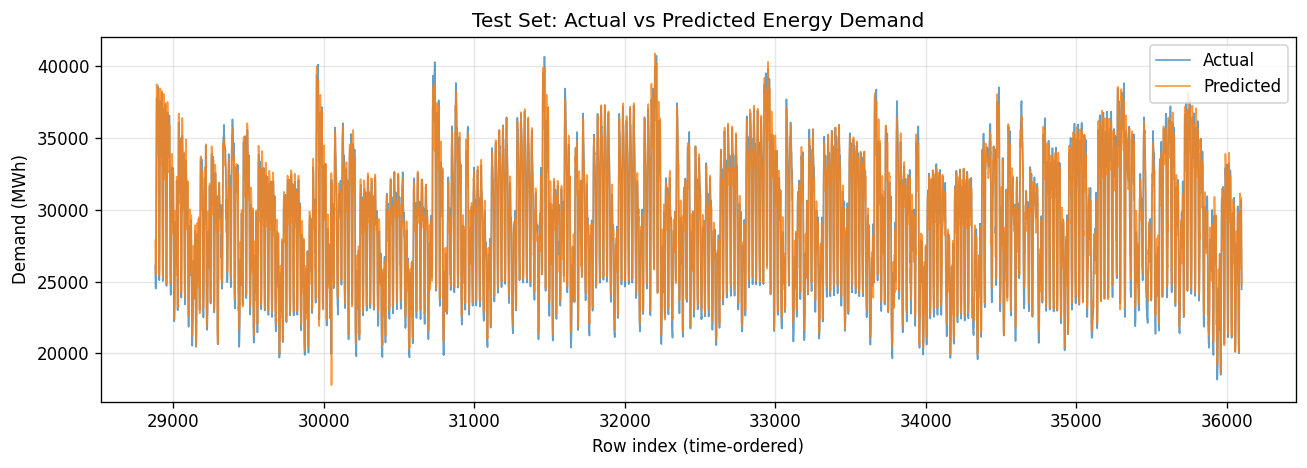

Final test MAE: 793.17 MWh


In [35]:
best_pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y_test.index, y_test.values, label="Actual", linewidth=1, alpha=0.7)
ax.plot(y_test.index, best_pred, label="Predicted", linewidth=1, alpha=0.8)
ax.set_title("Test Set: Actual vs Predicted Energy Demand")
ax.set_xlabel("Row index (time-ordered)")
ax.set_ylabel("Demand (MWh)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "test_actual_vs_predicted.png", dpi=150)
plt.show()

print("Final test MAE: %.2f MWh" % mean_absolute_error(y_test, best_pred))

Prediction and forecast

In [36]:
if not MODEL_PATH.exists():
    raise SystemExit("Model not found. Run the training cells above first.")

model = joblib.load(MODEL_PATH)
print("Loaded model from", MODEL_PATH)

# Use the last row of history as the record to predict
record = df_feat.iloc[-1].copy()
print("\nRecord to predict:")
print("  timestamp   :", record["timestamp"])
print("  temperature : %.1f C" % record["temperature_c"])
print("  humidity    : %.1f%%" % record["humidity"])
print("  wind speed  : %.1f km/h" % record["wind_speed_kmh"])
print("  is_weekend  : %d" % record["is_weekend"])

# Preprocess the record using the same pipeline (needs recent history for lags/MA)
history = df_clean.copy()
new_row = pd.DataFrame([record.to_dict()])
new_row["timestamp"] = pd.to_datetime(new_row["timestamp"])
df_tmp = pd.concat([history, new_row], ignore_index=True)
df_tmp = handle_missing(df_tmp, method="ffill")
df_tmp = add_time_features(df_tmp)
df_tmp = add_lag_features(df_tmp, lags=[1, 24, 168])
df_tmp = add_moving_average(df_tmp, windows=[7, 24])
row = df_tmp.iloc[[-1]].copy()

X_pred = row[feature_cols]
prediction = model.predict(X_pred)[0]
actual = record.get("energy_demand_mwh", None)

print("\n=== PREDICTION RESULT ===")
print("Timestamp   :", row["timestamp"].iloc[0])
print("Temperature : %.1f C" % row["temperature_c"].iloc[0])
print("Predicted energy demand: %.2f MWh" % prediction)
if pd.notna(actual):
    print("Actual demand: %.2f MWh" % actual)
    print("Absolute error: %.2f MWh" % abs(prediction - actual))

Loaded model from /content/models/energy_demand_model.pkl

Record to predict:
  timestamp   : 2018-12-31 22:00:00
  temperature : 275.1 C
  humidity    : 74.0%
  wind speed  : 1.0 km/h
  is_weekend  : 0

=== PREDICTION RESULT ===
Timestamp   : 2018-12-31 22:00:00
Temperature : 275.1 C
Predicted energy demand: 23167.23 MWh
Actual demand: 24455.00 MWh
Absolute error: 1287.77 MWh
